# Training Data 1 — Exploratory Data Analysis (EDA)

## Project Overview
This notebook explores the order, sales, profit, product, promotion, channel, and geographic fields in `TrainingData1.xlsx`.

**Workflow:** load data → inspect structure → assess data quality → create date-based fields → analyze KPIs and categories → explore trends and relationships → summarize findings.

> Keep `TrainingData1.xlsx` in the same folder as this notebook. In Google Colab, upload the Excel file when prompted.

## 1. Setup & Load Data

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme()
plt.rcParams["figure.figsize"] = (10, 5)

file_path = Path("/content/TrainingData1.csv")

if not file_path.exists():
    raise FileNotFoundError(
        f"{file_path} was not found. Please verify the file path."
    )

# The file is actually an Excel spreadsheet with a .csv extension.
# We must load it using pd.read_excel.
try:
    df = pd.read_excel(file_path)
except Exception as e:
    # Fallback with engine specified if needed
    df = pd.read_excel(file_path, engine='openpyxl')

display(df.head())

,Order ID,Order Date,Unit Cost,Price,Order Qty,Cost of Sales,Sales,Profit,Channel,Promotion Name,Product Name,Manufacturer,Product Sub Category,Product Category,Region,City,Country
0,7077,2013-03-18,76.094968,304.00,9,684.854710,2714.7200,2029.865290,Store,European Spring Promotion,Contoso SLR Camera M143 Grey,"Contoso, Ltd",Digital SLR Cameras,Cameras and camcorders,Europe,Moscow,Russia
1,117,2012-02-23,7.491753,12.99,4,29.967011,50.1414,20.174389,Store,European Spring Promotion,Contoso 512MB MP3 Player E51 Blue,"Contoso, Ltd",MP4&MP3,Audio,Europe,Moscow,Russia
2,7018,2012-01-11,10.122338,159.99,9,91.101039,1395.1128,1304.011761,Store,European Spring Promotion,Contoso DVD 9-Inch Player Portable M300 Silver,"Contoso, Ltd",Movie DVD,"Music, Movies and Audio Books",Europe,Moscow,Russia
3,140,2014-02-13,0.576153,25.69,18,10.370759,462.4200,452.049241,Store,North America Spring Promotion,NT Bluetooth Stereo Headphones E52 Pink,Northwind Traders,Bluetooth Headphones,Audio,North America,Bellevue,United States
4,491,2013-01-17,108.508777,304.00,9,976.578991,2614.4000,1637.821009,Online,Asian Spring Promotion,Contoso SLR Camera M143 Grey,"Contoso, Ltd",Digital SLR Cameras,Cameras and camcorders,Asia,Beijing,China


## 2. Basic Structure

In [10]:
print("Dataset shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nRandom sample:")
display(df.sample(min(5, len(df)), random_state=42))

Dataset shape: (15000, 17)
\nColumn names:
['Order ID', 'Order Date', 'Unit Cost', 'Price', 'Order Qty', 'Cost of Sales', 'Sales', 'Profit', 'Channel', 'Promotion Name', 'Product Name', 'Manufacturer', 'Product Sub Category', 'Product Category', 'Region', 'City', 'Country']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Order ID              15000 non-null  int64         
 1   Order Date            15000 non-null  datetime64[ns]
 2   Unit Cost             15000 non-null  float64       
 3   Price                 15000 non-null  float64       
 4   Order Qty             15000 non-null  int64         
 5   Cost of Sales         15000 non-null  float64       
 6   Sales                 15000 non-null  float64       
 7   Profit                15000 non-null  float64       
 8

,Order ID,Order Date,Unit Cost,Price,Order Qty,Cost of Sales,Sales,Profit,Channel,Promotion Name,Product Name,Manufacturer,Product Sub Category,Product Category,Region,City,Country
11499,17149,2014-09-27,605.224288,1299.00,10,6052.242877,12990.00,6937.757123,Store,No Discount,Adventure Works Laptop19W X1980 Red,Adventure Works,Laptops,Computers,North America,Milwaukee,United States
6475,9652,2013-05-21,13.951763,15.90,12,167.421156,184.44,17.018844,Online,Asian Summer Promotion,Contoso USB Wave Multi-Media Keyboard E280 Grey,"Contoso, Ltd",Computers Accessories,Computers,Asia,Beijing,China
13167,19653,2012-10-07,9.839122,9.99,6,59.034734,59.94,0.905266,Store,North America Holiday Promotion,Contoso DVD 38 DVD Storage Binder E25 Red,"Contoso, Ltd",Movie DVD,"Music, Movies and Audio Books",North America,Fredericksburg,United States
862,7509,2013-08-07,112.438130,358.00,12,1349.257558,4224.40,2875.142442,Store,North America Back-to-School Promotion,"Contoso SLR Camera 35"" M358 Grey","Contoso, Ltd",Digital SLR Cameras,Cameras and camcorders,North America,Parker,United States
5970,8894,2012-12-21,8.539564,19.90,9,76.856072,177.11,100.253928,Online,North America Spring Promotion,Contoso Battery charger - bike E200 White,"Contoso, Ltd",Computers Accessories,Computers,North America,Bethesda,United States


In [11]:
print("Numeric summary:")
display(df.describe().T)

print("Categorical summary:")
display(df.describe(include="object").T)

Numeric summary:


,count,mean,min,25%,50%,75%,max,std
Order ID,15000.0,11209.3166,1.0,5629.75,11238.5,16789.5,22352.0,6451.583877
Order Date,15000,2013-04-03 02:00:23.040000,2011-12-06 00:00:00,2012-06-28 00:00:00,2013-02-19 00:00:00,2013-12-21 00:00:00,2014-12-05 00:00:00,NaN
Unit Cost,15000.0,124.425132,0.001576,16.847345,69.688876,164.348636,1896.133845,163.569912
Price,15000.0,296.514697,0.95,59.0,205.0,366.0,2899.99,345.985232
Order Qty,15000.0,16.741733,4.0,9.0,10.0,13.0,1560.0,43.490032
Cost of Sales,15000.0,1586.954833,0.015756,189.67742,752.75232,2006.030237,42991.137192,2408.96143
Sales,15000.0,3692.783986,4.75,645.0,2301.17575,4767.72,78312.0,4917.886955
Profit,15000.0,2105.829152,-838.426733,242.198732,1012.683637,2573.128436,55692.569522,3387.145437


Categorical summary:


,count,unique,top,freq
Channel,15000,4,Store,9981
Promotion Name,15000,10,No Discount,5207
Product Name,15000,1638,WWI Desktop PC1.80 E1802 White,25
Manufacturer,15000,10,"Contoso, Ltd",4891
Product Sub Category,15000,22,Computers Accessories,1642
Product Category,15000,6,Computers,5359
Region,15000,3,North America,8869
City,15000,263,Beijing,1398
Country,15000,34,United States,8510


## 3. Data Quality Checks

In [13]:
# Missing values
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)
display(missing_summary)

# Duplicate rows and duplicate Order IDs
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Order IDs:", df["Order ID"].duplicated().sum())

# Validate data types
print("Order Date dtype before conversion:", df["Order Date"].dtype)
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
print("Invalid/missing dates after conversion:", df["Order Date"].isna().sum())

# Basic checks for negative quantities and monetary fields
for col in ["Unit Cost", "Price", "Order Qty", "Cost of Sales", "Sales", "Profit"]:
    if col in df.columns:
        print(f"Negative values in {col}: {(df[col] < 0).sum()}")

,Missing Count,Missing Percent
Order ID,0,0.0
Order Date,0,0.0
Unit Cost,0,0.0
Price,0,0.0
Order Qty,0,0.0
Cost of Sales,0,0.0
Sales,0,0.0
Profit,0,0.0
Channel,0,0.0
Promotion Name,0,0.0


Exact duplicate rows: 0
Duplicate Order IDs: 0
Order Date dtype before conversion: datetime64[ns]
Invalid/missing dates after conversion: 0
Negative values in Unit Cost: 0
Negative values in Price: 0
Negative values in Order Qty: 0
Negative values in Cost of Sales: 0
Negative values in Sales: 0
Negative values in Profit: 213


## 4. Derived Fields

In [14]:
# Date-derived fields support time-based analysis.
df["Year"] = df["Order Date"].dt.year
df["Quarter"] = df["Order Date"].dt.to_period("Q").astype("string")
df["Month Number"] = df["Order Date"].dt.month
df["Month"] = df["Order Date"].dt.month_name()
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype("string")
df["Day of Week"] = df["Order Date"].dt.day_name()
df["Day of Month"] = df["Order Date"].dt.day
df["Is Weekend"] = df["Order Date"].dt.dayofweek >= 5

display(df[["Order Date", "Year", "Quarter", "Month", "Year-Month",
            "Day of Week", "Day of Month", "Is Weekend"]].head())

,Order Date,Year,Quarter,Month,Year-Month,Day of Week,Day of Month,Is Weekend
0,2013-03-18,2013,2013Q1,March,2013-03,Monday,18,False
1,2012-02-23,2012,2012Q1,February,2012-02,Thursday,23,False
2,2012-01-11,2012,2012Q1,January,2012-01,Wednesday,11,False
3,2014-02-13,2014,2014Q1,February,2014-02,Thursday,13,False
4,2013-01-17,2013,2013Q1,January,2013-01,Thursday,17,False


## 5. Categorical Breakdowns

In [15]:
categorical_cols = [
    "Channel", "Promotion Name", "Manufacturer", "Product Sub Category",
    "Product Category", "Region", "Country"
]

for col in categorical_cols:
    print(f"\\n{col}: {df[col].nunique()} unique values")
    display(df[col].value_counts(dropna=False).head(15).rename("Record Count").to_frame())

\nChannel: 4 unique values


,Record Count
Channel,
Store,9981
Online,2351
Reseller,1784
Catalog,884


\nPromotion Name: 10 unique values


,Record Count
Promotion Name,
No Discount,5207
North America Spring Promotion,2079
North America Back-to-School Promotion,2040
North America Holiday Promotion,1415
European Holiday Promotion,1025
Asian Holiday Promotion,750
Asian Spring Promotion,745
European Spring Promotion,721
European Back-to-Scholl Promotion,520


\nManufacturer: 10 unique values


...

,Record Count
Product Category,
Computers,5359
Cameras and camcorders,3590
Cell phones,2609
TV and Video,1878
"Music, Movies and Audio Books",832
Audio,732


\nRegion: 3 unique values


,Record Count
Region,
North America,8869
Europe,3081
Asia,3050


\nCountry: 34 unique values


,Record Count
Country,
United States,8510
China,1673
Germany,1118
France,781
United Kingdom,477
Canada,359
Japan,298
Russia,166
India,152


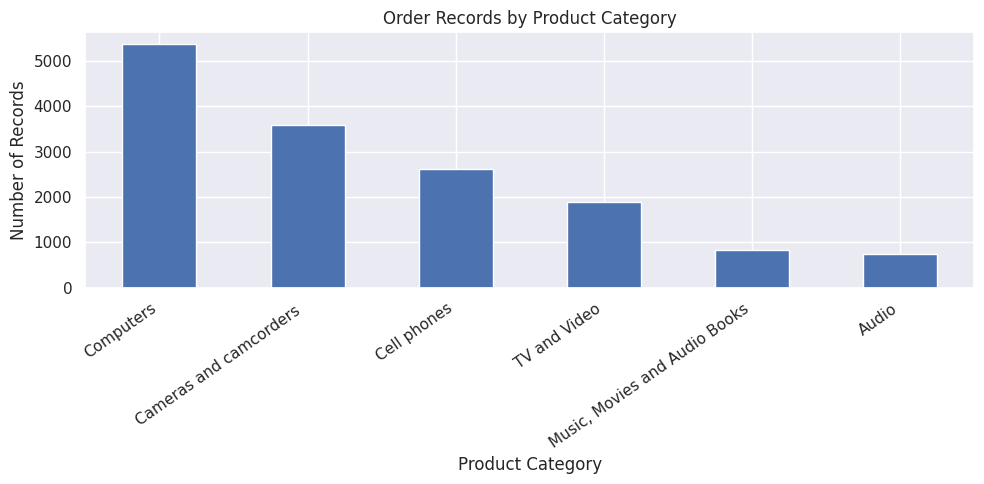

In [16]:
# Order records by product category
category_counts = df["Product Category"].value_counts()
category_counts.plot(kind="bar")
plt.title("Order Records by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 6. Overall Business KPIs

In [17]:
kpi_summary = pd.Series({
    "Order Records": len(df),
    "Unique Order IDs": df["Order ID"].nunique(),
    "Total Quantity": df["Order Qty"].sum(),
    "Total Sales": df["Sales"].sum(),
    "Total Cost of Sales": df["Cost of Sales"].sum(),
    "Total Profit": df["Profit"].sum(),
    "Average Sales per Record": df["Sales"].mean(),
    "Average Profit per Record": df["Profit"].mean(),
    "Overall Profit Margin (%)": (df["Profit"].sum() / df["Sales"].sum() * 100)
        if df["Sales"].sum() != 0 else np.nan
})
display(kpi_summary.to_frame("Value").round(2))

,Value
Order Records,15000.00
Unique Order IDs,15000.00
Total Quantity,251126.00
Total Sales,55391759.79
Total Cost of Sales,23804322.50
Total Profit,31587437.29
Average Sales per Record,3692.78
Average Profit per Record,2105.83
Overall Profit Margin (%),57.03


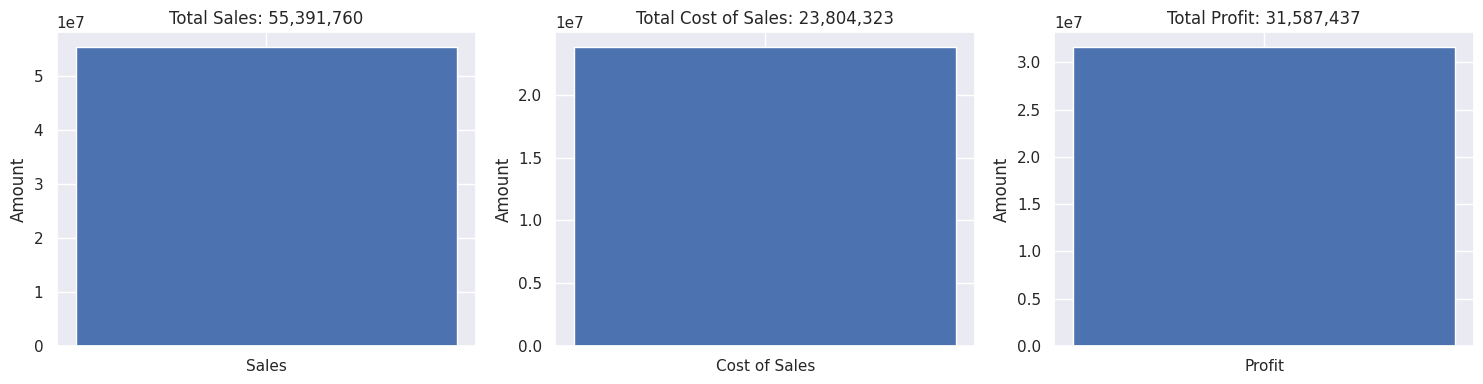

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
kpis = [
    ("Sales", df["Sales"].sum()),
    ("Cost of Sales", df["Cost of Sales"].sum()),
    ("Profit", df["Profit"].sum())
]
axes[0].bar([kpis[0][0]], [kpis[0][1]])
axes[1].bar([kpis[1][0]], [kpis[1][1]])
axes[2].bar([kpis[2][0]], [kpis[2][1]])
for ax, (label, value) in zip(axes, kpis):
    ax.set_title(f"Total {label}: {value:,.0f}")
    ax.set_ylabel("Amount")
plt.tight_layout()
plt.show()

## 7. Sales & Profit Over Time

,Year-Month,Sales,Profit,Cost_of_Sales,Order_Records
0,2011-12,1.259710e+06,7.371398e+05,522569.970766,443
1,2012-01,1.410162e+06,7.777595e+05,632401.996780,515
2,2012-02,1.201722e+06,7.155134e+05,486208.428124,434
3,2012-03,1.938859e+06,1.125530e+06,813329.136294,607
4,2012-04,2.001381e+06,1.099239e+06,902141.454433,645


,Year-Month,Sales,Profit,Cost_of_Sales,Order_Records
32,2014-08,1.542918e+06,847654.469135,695263.677865,336
33,2014-09,1.364508e+06,787739.044877,576769.286123,341
34,2014-10,1.534730e+06,874228.013457,660501.948043,344
35,2014-11,1.436796e+06,802672.105192,634123.579308,300
36,2014-12,1.599271e+05,90347.046130,69580.029870,44


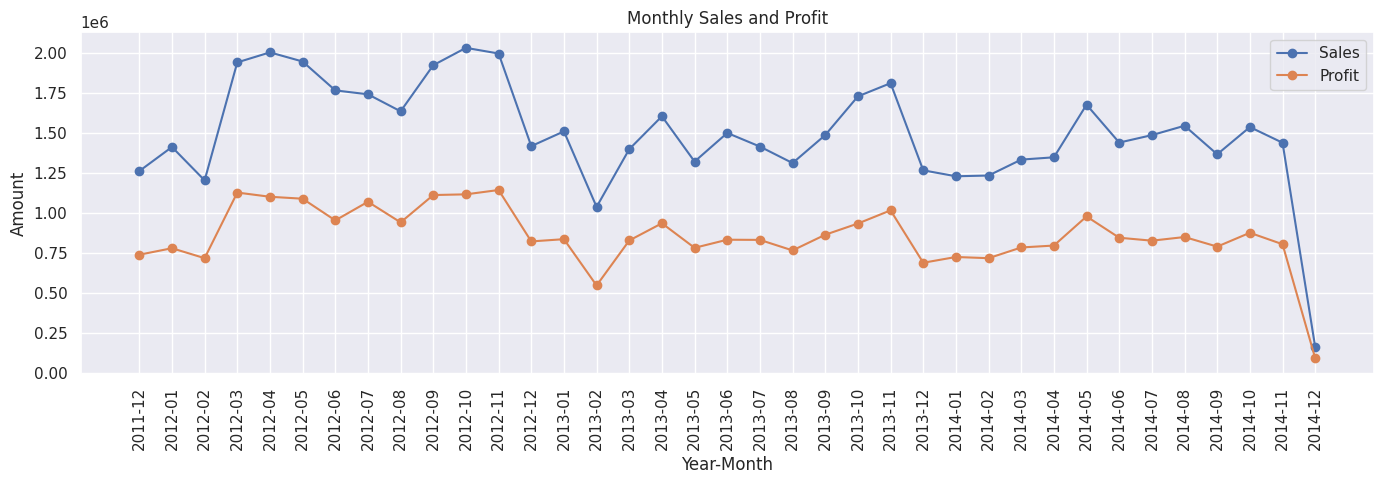

In [19]:
monthly = (
    df.dropna(subset=["Order Date"])
      .groupby("Year-Month", as_index=False)
      .agg(Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Cost_of_Sales=("Cost of Sales", "sum"),
           Order_Records=("Order ID", "size"))
      .sort_values("Year-Month")
)

display(monthly.head())
display(monthly.tail())

plt.figure(figsize=(14, 5))
plt.plot(monthly["Year-Month"], monthly["Sales"], marker="o", label="Sales")
plt.plot(monthly["Year-Month"], monthly["Profit"], marker="o", label="Profit")
plt.title("Monthly Sales and Profit")
plt.xlabel("Year-Month")
plt.ylabel("Amount")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

,Year,Sales,Profit,Cost_of_Sales,Quantity,Order_Records
0,2011,1.259710e+06,7.371398e+05,5.225700e+05,5359,443
1,2012,2.099365e+07,1.194947e+07,9.044179e+06,81150,6420
2,2013,1.736657e+07,9.838662e+06,7.527910e+06,73751,4497
3,2014,1.577183e+07,9.062167e+06,6.709664e+06,90866,3640


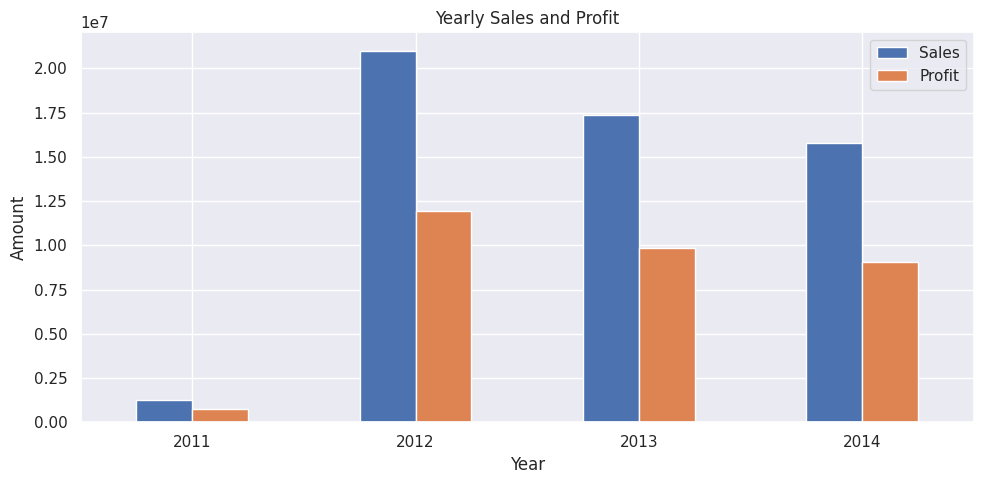

In [20]:
yearly = (
    df.groupby("Year", dropna=False)
      .agg(Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Cost_of_Sales=("Cost of Sales", "sum"),
           Quantity=("Order Qty", "sum"),
           Order_Records=("Order ID", "size"))
      .reset_index()
)
display(yearly)

yearly.set_index("Year")[["Sales", "Profit"]].plot(kind="bar")
plt.title("Yearly Sales and Profit")
plt.xlabel("Year")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Product Category & Subcategory Analysis

,Sales,Profit,Cost_of_Sales,Quantity,Records,Profit Margin (%)
Product Category,,,,,,
Computers,21306971.17,12162419.23,9144551.95,69425,5359,57.08
Cameras and camcorders,17048931.69,10102801.66,6946130.04,43893,3590,59.26
TV and Video,9107839.47,4823734.62,4284104.85,22714,1878,52.96
Cell phones,5841155.77,3285926.33,2555229.44,96074,2609,56.25
"Music, Movies and Audio Books",1057480.36,635285.12,422195.24,9953,832,60.08
Audio,1029381.32,577270.33,452110.99,9067,732,56.08


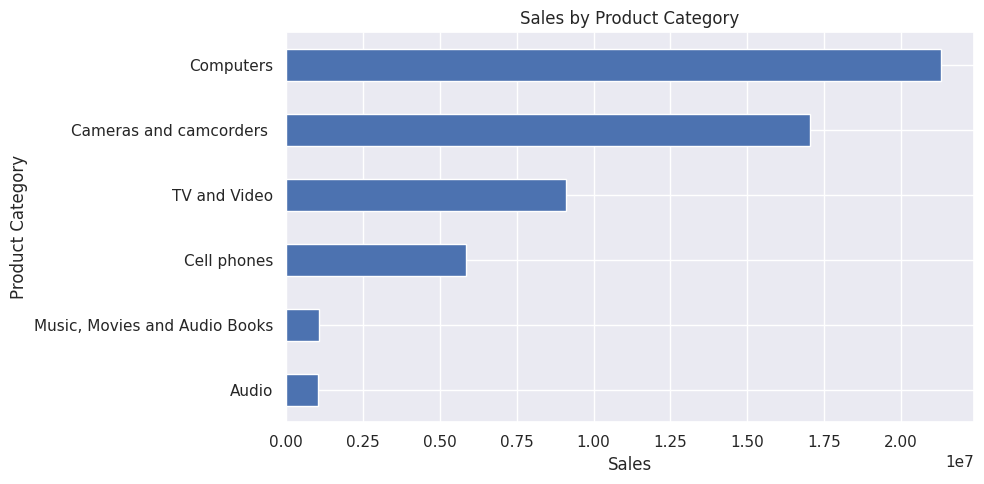

In [21]:
category_performance = (
    df.groupby("Product Category", dropna=False)
      .agg(Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Cost_of_Sales=("Cost of Sales", "sum"),
           Quantity=("Order Qty", "sum"),
           Records=("Order ID", "size"))
      .sort_values("Sales", ascending=False)
)
category_performance["Profit Margin (%)"] = (
    category_performance["Profit"] / category_performance["Sales"] * 100
).replace([np.inf, -np.inf], np.nan)
display(category_performance.round(2))

category_performance["Sales"].sort_values().plot(kind="barh")
plt.title("Sales by Product Category")
plt.xlabel("Sales")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

,Sales,Profit,Quantity,Records
Product Sub Category,,,,
Camcorders,8456120.92,4972852.90,12091,987
Projectors & Screens,7036174.58,4145050.32,10319,874
Laptops,6403174.09,3763974.47,10265,812
Digital SLR Cameras,5731189.62,3503777.56,12969,1069
Home Theater System,4737967.56,2470355.41,10342,848
Desktops,3491787.15,1762032.54,9599,412
Smart phones & PDAs,2822294.79,1585115.38,10184,855
Digital Cameras,2539792.28,1455482.33,12418,1012
Car Video,2093143.99,1065879.48,5768,490


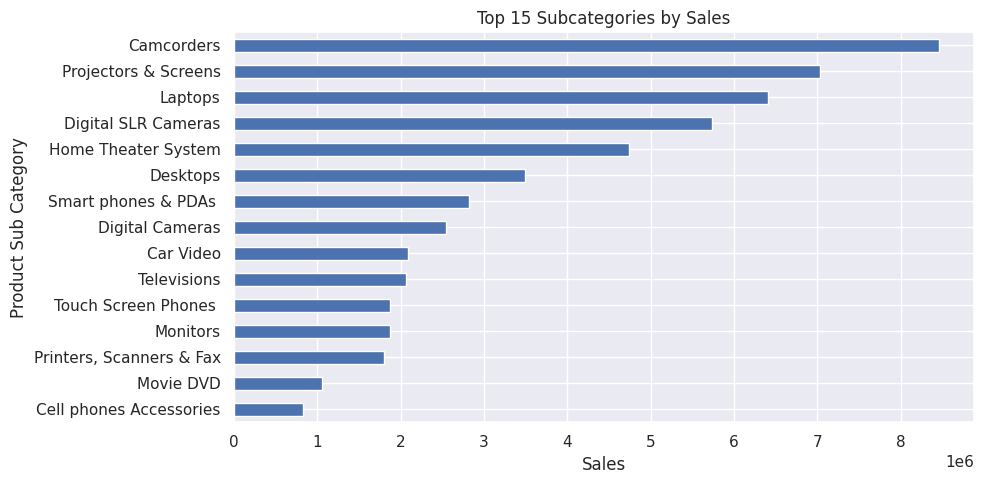

In [22]:
subcategory_performance = (
    df.groupby("Product Sub Category", dropna=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
           Quantity=("Order Qty", "sum"), Records=("Order ID", "size"))
      .sort_values("Sales", ascending=False)
)
display(subcategory_performance.head(15).round(2))

subcategory_performance.head(15).sort_values("Sales").plot(kind="barh", y="Sales", legend=False)
plt.title("Top 15 Subcategories by Sales")
plt.xlabel("Sales")
plt.ylabel("Product Sub Category")
plt.tight_layout()
plt.show()

## 9. Channel & Promotion Analysis

,Sales,Profit,Cost_of_Sales,Quantity,Records,Profit Margin (%)
Channel,,,,,,
Store,31720647.24,18049279.21,13671368.03,142219,9981,56.90
Online,11500207.32,6529716.97,4970490.35,53057,2351,56.78
Reseller,7170613.80,4112546.39,3058067.41,31044,1784,57.35
Catalog,5000291.43,2895894.72,2104396.72,24806,884,57.91


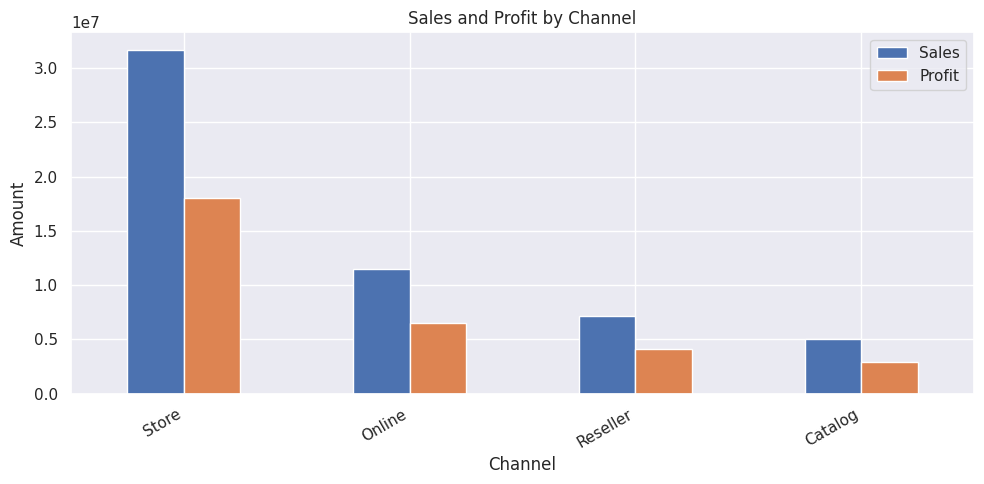

In [23]:
channel_performance = (
    df.groupby("Channel", dropna=False)
      .agg(Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Cost_of_Sales=("Cost of Sales", "sum"),
           Quantity=("Order Qty", "sum"),
           Records=("Order ID", "size"))
      .sort_values("Sales", ascending=False)
)
channel_performance["Profit Margin (%)"] = (
    channel_performance["Profit"] / channel_performance["Sales"] * 100
).replace([np.inf, -np.inf], np.nan)
display(channel_performance.round(2))

channel_performance[["Sales", "Profit"]].plot(kind="bar")
plt.title("Sales and Profit by Channel")
plt.xlabel("Channel")
plt.ylabel("Amount")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

,Sales,Profit,Quantity,Records,Profit Margin (%)
Promotion Name,,,,,
No Discount,18329360.07,10604149.81,80062,5207,57.85
North America Back-to-School Promotion,8455760.98,4800289.81,39393,2040,56.77
North America Holiday Promotion,6451628.91,3574758.04,30392,1415,55.41
North America Spring Promotion,6374333.07,3566777.31,30631,2079,55.96
Asian Holiday Promotion,3615193.99,2078391.08,17004,750,57.49
European Holiday Promotion,3083455.95,1745371.43,12328,1025,56.60
European Spring Promotion,2739318.98,1498235.52,13205,721,54.69
Asian Spring Promotion,2396000.66,1411799.62,10980,745,58.92
Asian Summer Promotion,2278683.18,1315490.48,9768,498,57.73


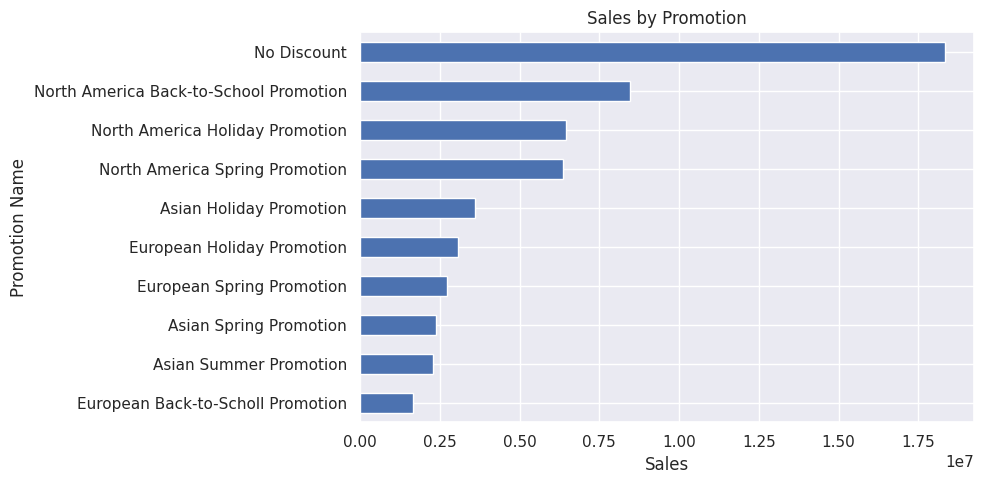

In [24]:
promotion_performance = (
    df.groupby("Promotion Name", dropna=False)
      .agg(Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Quantity=("Order Qty", "sum"),
           Records=("Order ID", "size"))
      .sort_values("Sales", ascending=False)
)
promotion_performance["Profit Margin (%)"] = (
    promotion_performance["Profit"] / promotion_performance["Sales"] * 100
).replace([np.inf, -np.inf], np.nan)
display(promotion_performance.round(2))

promotion_performance["Sales"].sort_values().plot(kind="barh")
plt.title("Sales by Promotion")
plt.xlabel("Sales")
plt.ylabel("Promotion Name")
plt.tight_layout()
plt.show()

## 10. Geographic Analysis

,Sales,Profit,Quantity,Records,Profit Margin (%)
Region,,,,,
North America,32783557.02,18668830.51,148953,8869,56.95
Asia,12412345.06,7144693.83,57581,3050,57.56
Europe,10195857.72,5773912.94,44592,3081,56.63


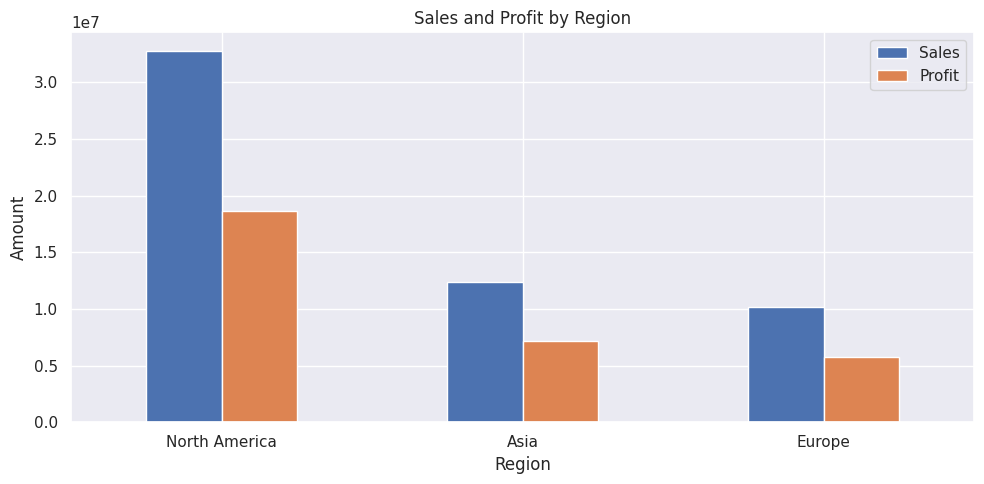

In [25]:
region_performance = (
    df.groupby("Region", dropna=False)
      .agg(Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Quantity=("Order Qty", "sum"),
           Records=("Order ID", "size"))
      .sort_values("Sales", ascending=False)
)
region_performance["Profit Margin (%)"] = (
    region_performance["Profit"] / region_performance["Sales"] * 100
).replace([np.inf, -np.inf], np.nan)
display(region_performance.round(2))

region_performance[["Sales", "Profit"]].plot(kind="bar")
plt.title("Sales and Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Sales,Profit,Quantity,Records
Country,,,,
United States,31635240.56,17999958.60,143862,8510
China,7557973.80,4392369.47,35407,1673
Germany,4314956.37,2473281.53,17789,1118
France,2628400.62,1401589.64,11850,781
United Kingdom,1324267.22,729551.63,5856,477
Canada,1148316.45,668871.91,5091,359
Japan,958334.38,555052.32,4749,298
Australia,632642.51,344234.44,2227,149
India,598404.61,357657.33,2585,152


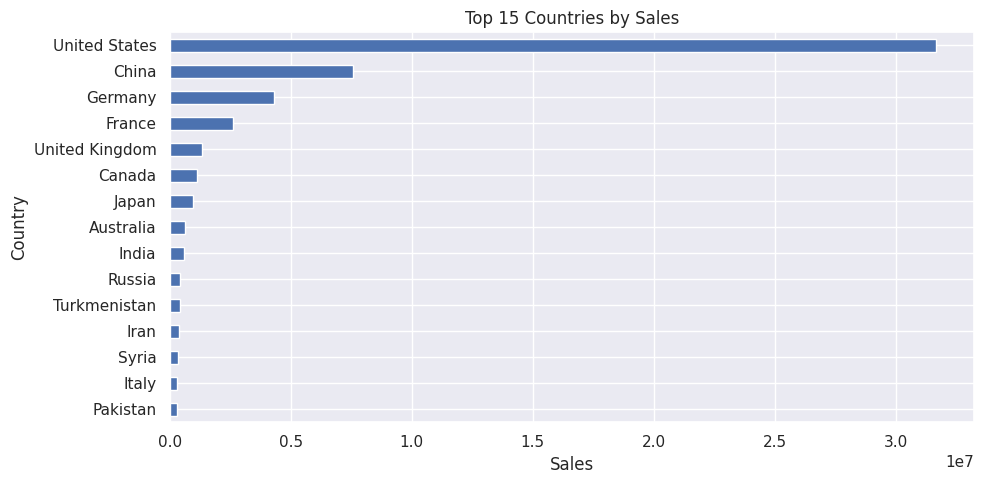

In [26]:
country_performance = (
    df.groupby("Country", dropna=False)
      .agg(Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Quantity=("Order Qty", "sum"),
           Records=("Order ID", "size"))
      .sort_values("Sales", ascending=False)
)
display(country_performance.head(15).round(2))

country_performance.head(15).sort_values("Sales").plot(kind="barh", y="Sales", legend=False)
plt.title("Top 15 Countries by Sales")
plt.xlabel("Sales")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 11. Manufacturer, Relationships & Validation

,Sales,Profit,Quantity,Records,Profit Margin (%)
Manufacturer,,,,,
"Fabrikam, Inc.",12054281.48,7158976.97,19599,1605,59.39
"Contoso, Ltd",9996750.02,5670159.66,124133,4891,56.72
Adventure Works,7467703.69,4158548.24,16300,1125,55.69
"Proseware, Inc.",5996829.03,3513124.65,19330,1639,58.58
Wide World Importers,5700910.02,3198143.27,14396,990,56.10
A. Datum Corporation,4404982.01,2608508.25,16601,1342,59.22
The Phone Company,4386164.26,2476148.28,15744,1314,56.45
Southridge Video,3112730.48,1610013.07,18339,1540,51.72
"Litware, Inc.",2134836.83,1120286.89,4020,348,52.48


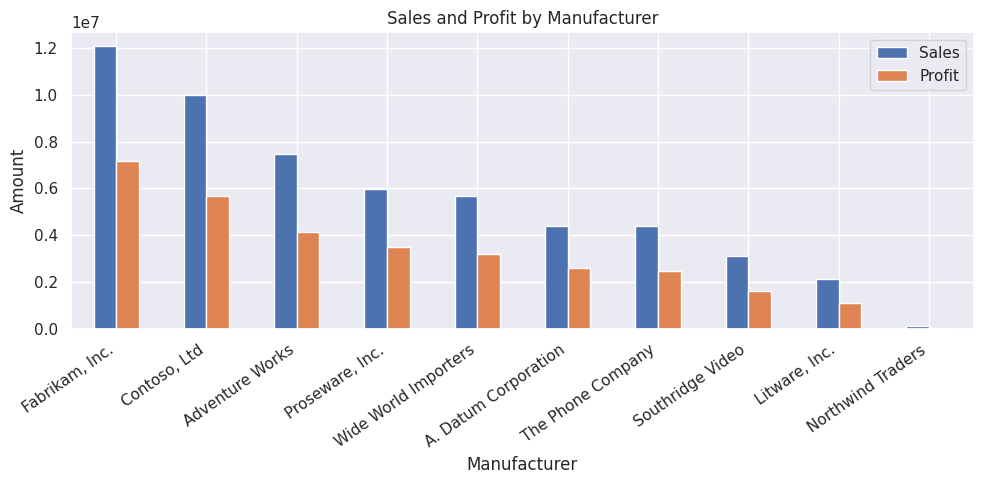

In [27]:
manufacturer_performance = (
    df.groupby("Manufacturer", dropna=False)
      .agg(Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Quantity=("Order Qty", "sum"),
           Records=("Order ID", "size"))
      .sort_values("Sales", ascending=False)
)
manufacturer_performance["Profit Margin (%)"] = (
    manufacturer_performance["Profit"] / manufacturer_performance["Sales"] * 100
).replace([np.inf, -np.inf], np.nan)
display(manufacturer_performance.round(2))

manufacturer_performance[["Sales", "Profit"]].plot(kind="bar")
plt.title("Sales and Profit by Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Amount")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

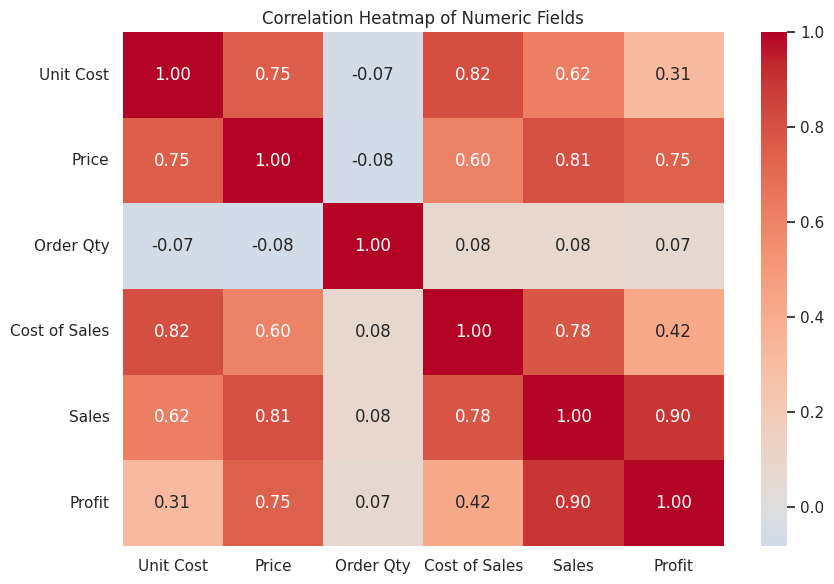

In [28]:
# Correlation between numeric fields
numeric_cols = ["Unit Cost", "Price", "Order Qty", "Cost of Sales", "Sales", "Profit"]
corr = df[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numeric Fields")
plt.tight_layout()
plt.show()

,Metric,Matching Rows,Total Rows,Matching Percent
0,Sales difference is approximately zero,7145,15000,47.63
1,Cost difference is approximately zero,15000,15000,100.00


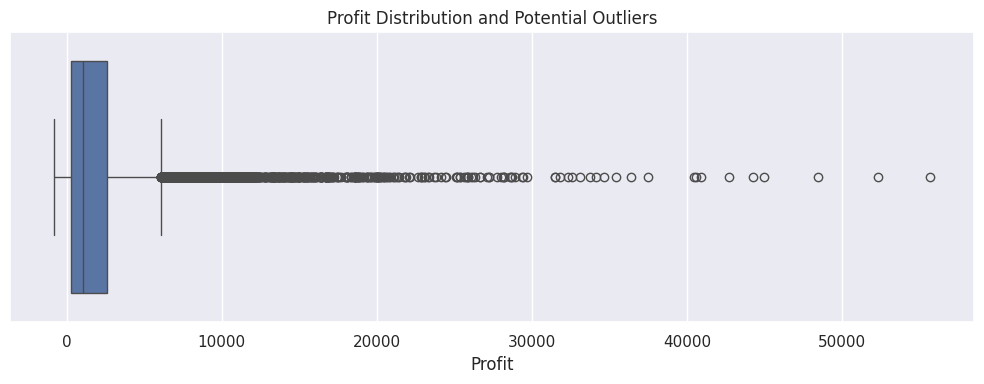

,count,mean,std,min,25%,50%,75%,max
Sales,15000.0,3692.78,4917.89,4.75,645.00,2301.18,4767.72,78312.00
Cost of Sales,15000.0,1586.95,2408.96,0.02,189.68,752.75,2006.03,42991.14
Profit,15000.0,2105.83,3387.15,-838.43,242.20,1012.68,2573.13,55692.57


In [29]:
# Check whether the recorded Sales/Cost of Sales values match simple price/quantity calculations.
# These are diagnostic checks only; the original fields are not overwritten.
df["Calculated Sales (Price x Qty)"] = df["Price"] * df["Order Qty"]
df["Sales Difference"] = df["Sales"] - df["Calculated Sales (Price x Qty)"]
df["Calculated Cost (Unit Cost x Qty)"] = df["Unit Cost"] * df["Order Qty"]
df["Cost Difference"] = df["Cost of Sales"] - df["Calculated Cost (Unit Cost x Qty)"]

validation_summary = pd.DataFrame({
    "Metric": ["Sales difference is approximately zero",
               "Cost difference is approximately zero"],
    "Matching Rows": [
        np.isclose(df["Sales Difference"], 0, atol=0.01).sum(),
        np.isclose(df["Cost Difference"], 0, atol=0.01).sum()
    ],
    "Total Rows": [len(df), len(df)]
})
validation_summary["Matching Percent"] = (
    validation_summary["Matching Rows"] / validation_summary["Total Rows"] * 100
).round(2)
display(validation_summary)

# Profit distribution and potential outliers
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["Profit"])
plt.title("Profit Distribution and Potential Outliers")
plt.xlabel("Profit")
plt.tight_layout()
plt.show()

display(df[["Sales", "Cost of Sales", "Profit"]].describe().T.round(2))

## 12. Summary & Key Findings

In [30]:
print("DATASET SUMMARY")
print("-" * 50)
print(f"Rows: {len(df):,}")
print(f"Columns (including derived/validation fields): {df.shape[1]}")
print(f"Order date range: {df['Order Date'].min()} to {df['Order Date'].max()}")
print(f"Unique Order IDs: {df['Order ID'].nunique():,}")
print(f"Total quantity: {df['Order Qty'].sum():,.0f}")
print(f"Total sales: {df['Sales'].sum():,.2f}")
print(f"Total cost of sales: {df['Cost of Sales'].sum():,.2f}")
print(f"Total profit: {df['Profit'].sum():,.2f}")
profit_margin = df['Profit'].sum() / df['Sales'].sum() * 100 if df['Sales'].sum() else np.nan
print(f"Overall profit margin: {profit_margin:.2f}%")
print(f"Exact duplicate rows in original data: {df.duplicated(subset=['Order ID', 'Order Date', 'Unit Cost', 'Price', 'Order Qty', 'Cost of Sales', 'Sales', 'Profit', 'Channel', 'Promotion Name', 'Product Name', 'Manufacturer', 'Product Sub Category', 'Product Category', 'Region', 'City', 'Country']).sum()}")

print("\\nTop categories by sales:")
display(category_performance.head(5).round(2))
print("\\nTop channels by sales:")
display(channel_performance.head(5).round(2))
print("\\nTop regions by sales:")
display(region_performance.head(5).round(2))

print("\\nInterpretation note: Use the tables and charts above to identify strong/weak categories, profitable channels, geographic patterns, and whether sales/cost calculations align with the source data.")

DATASET SUMMARY
--------------------------------------------------
Rows: 15,000
Columns (including derived/validation fields): 29
Order date range: 2011-12-06 00:00:00 to 2014-12-05 00:00:00
Unique Order IDs: 15,000
Total quantity: 251,126
Total sales: 55,391,759.79
Total cost of sales: 23,804,322.50
Total profit: 31,587,437.29
Overall profit margin: 57.03%
Exact duplicate rows in original data: 0
\nTop categories by sales:


,Sales,Profit,Cost_of_Sales,Quantity,Records,Profit Margin (%)
Product Category,,,,,,
Computers,21306971.17,12162419.23,9144551.95,69425,5359,57.08
Cameras and camcorders,17048931.69,10102801.66,6946130.04,43893,3590,59.26
TV and Video,9107839.47,4823734.62,4284104.85,22714,1878,52.96
Cell phones,5841155.77,3285926.33,2555229.44,96074,2609,56.25
"Music, Movies and Audio Books",1057480.36,635285.12,422195.24,9953,832,60.08


\nTop channels by sales:


,Sales,Profit,Cost_of_Sales,Quantity,Records,Profit Margin (%)
Channel,,,,,,
Store,31720647.24,18049279.21,13671368.03,142219,9981,56.90
Online,11500207.32,6529716.97,4970490.35,53057,2351,56.78
Reseller,7170613.80,4112546.39,3058067.41,31044,1784,57.35
Catalog,5000291.43,2895894.72,2104396.72,24806,884,57.91


\nTop regions by sales:


,Sales,Profit,Quantity,Records,Profit Margin (%)
Region,,,,,
North America,32783557.02,18668830.51,148953,8869,56.95
Asia,12412345.06,7144693.83,57581,3050,57.56
Europe,10195857.72,5773912.94,44592,3081,56.63


\nInterpretation note: Use the tables and charts above to identify strong/weak categories, profitable channels, geographic patterns, and whether sales/cost calculations align with the source data.
